# SSA и t-SNE

## Импорты и параметры

In [1]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from SSA_lib import SSA
from my_lib import HankelMatrix, prepare_time_series

START = 7007
N_SAMPLES = 450 * 10
WINDOW = 500
N_COMPONENTS = 5
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True})

## Запись ходьбы

Используем модуль ускорения без вычитания среднего.

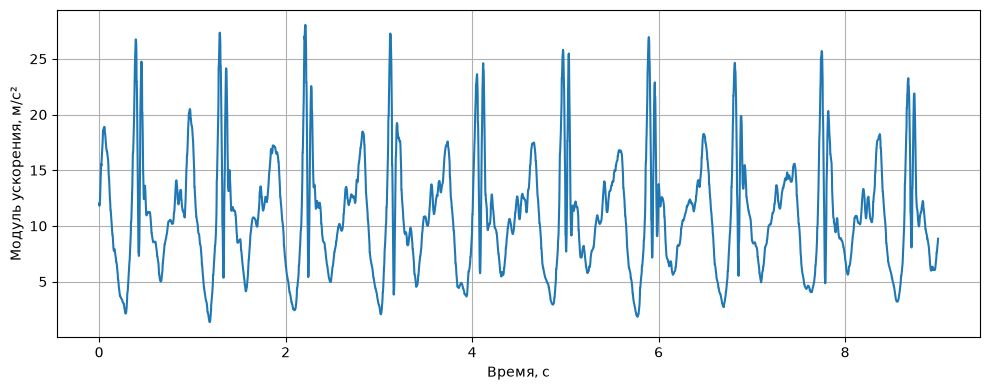

In [2]:
signal, time = prepare_time_series('data/long_walk_100_acc.csv', centred=False)
x_acc = signal[START:START + N_SAMPLES]
t = time[START:START + N_SAMPLES]
t = t - t[0]

plt.plot(t, x_acc)
plt.xlabel('Время, с')
plt.ylabel('Модуль ускорения, м/с²')
plt.tight_layout()
plt.show()

## Восстановление SSA

Суммируем первые пять компонент при окне 500. Сравниваем исходный и восстановленный сигналы на одном фрагменте.

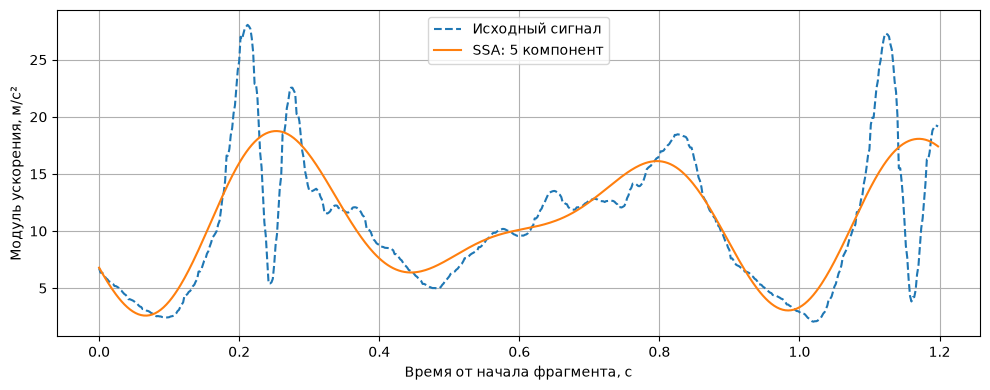

In [3]:
accel_ssa = SSA(x_acc, WINDOW, n_components=N_COMPONENTS)
x_acc_clear = accel_ssa.reconstruct(slice(0, N_COMPONENTS)).to_numpy()

zoom = slice(1000, 1600)
plt.plot(t[zoom] - t[1000], x_acc[zoom], '--', label='Исходный сигнал')
plt.plot(t[zoom] - t[1000], x_acc_clear[zoom], label='SSA: 5 компонент')
plt.xlabel('Время от начала фрагмента, с')
plt.ylabel('Модуль ускорения, м/с²')
plt.legend()
plt.tight_layout()
plt.show()

## Окна и t-SNE

Как в исходном коде, передаём все 4001 окно в t-SNE с тремя выходными координатами.

In [4]:
X = HankelMatrix(x_acc_clear, WINDOW)
tsne = TSNE(random_state=0, n_components=3)
X_tsne = tsne.fit_transform(X)
X_tsne.shape

(4001, 3)